In [89]:
import statsmodels.api as sm
import pandas as pd
from patsy import dmatrices
import numpy as np 

Рабочий диапазон амплитуд, определенный экспериментально:
За 1 минуту 32 с амплитуда упала примерно в 1,5 раза. Период колебания приблизительно 4.38 с (21 колебание)

## Расчет параметров устновки и их ошибок

In [90]:
# измерение параметров установки
l = 216*10**(-2) # m
sigma_l = 0.5*10**(-3) # m, половина цены
R = 115.5*10**(-3) # m
sigma_R = 0.5*10**(-3)  # m
r = 30.2*10**(-3) # m
sigma_r = 0.3*10**(-3)  # m

# расчет высоты
z = (l**2 - R**2)**0.5
print(f'z = {z} m')

# замеры для пустой установки
t_0 = 60+32+0.77
n_0 = 21

# расчет k
k = 9.81*R*r/(4*np.pi**2*z)
print(f"k = {k}")

z = 2.1569097686273295 m
k = 0.0004018520798981878


In [91]:
# вывод формул ошибки константы k и расчет ее абсолюнтой ошибки
import sympy as sp
R_sym, r_sym, l_sym, g_sym = sp.symbols('R r l g')
k_func = sp.Function('k')(r_sym, R_sym, l_sym)
k_r = sp.Derivative(k_func, r_sym)
k_R = sp.Derivative(k_func, R_sym)
k_l = sp.Derivative(k_func, l_sym)

k_sym = g_sym*R_sym*r_sym/(4*sp.pi**2*sp.sqrt(l_sym**2 - R_sym**2))
dk_dr = sp.Derivative(k_sym, r_sym, evaluate=True)
dk_dR = sp.Derivative(k_sym, R_sym, evaluate=True)
dk_dl = sp.Derivative(k_sym, l_sym, evaluate=True)

k_eq_1 = sp.Eq(k_r, dk_dr)
k_eq_2 = sp.Eq(k_R, dk_dR)
k_eq_3 = sp.Eq(k_l, dk_dl)

display(k_eq_1, k_eq_2, k_eq_3)

delta_r = sp.symbols(r'\Delta{r}')
delta_R = sp.symbols(r'\Delta{R}')
delta_l = sp.symbols(r'\Delta{l}')
sigma_k = sp.symbols(r'\sigma_k')

term1 = sp.Pow(dk_dr * delta_r, 2, evaluate=False)
term2 = sp.Pow(dk_dR * delta_R, 2, evaluate=False)
term3 = sp.Pow(dk_dl * delta_l, 2, evaluate=False)

result_sigma = sp.Eq(sigma_k, sp.sqrt(term1 + term2 + term3))

display(result_sigma)

display(k_sym)




Eq(Derivative(k(r, R, l), r), R*g/(4*pi**2*sqrt(-R**2 + l**2)))

Eq(Derivative(k(r, R, l), R), R**2*g*r/(4*pi**2*(-R**2 + l**2)**(3/2)) + g*r/(4*pi**2*sqrt(-R**2 + l**2)))

Eq(Derivative(k(r, R, l), l), -R*g*l*r/(4*pi**2*(-R**2 + l**2)**(3/2)))

Eq(\sigma_k, sqrt((\Delta{R}*(R**2*g*r/(4*pi**2*(-R**2 + l**2)**(3/2)) + g*r/(4*pi**2*sqrt(-R**2 + l**2))))**2 + (R*\Delta{r}*g/(4*pi**2*sqrt(-R**2 + l**2)))**2 + (-R*\Delta{l}*g*l*r/(4*pi**2*(-R**2 + l**2)**(3/2)))**2))

R*g*r/(4*pi**2*sqrt(-R**2 + l**2))

In [92]:
subst_dict = {R_sym : R, g_sym: 9.81, r_sym : r, l_sym : l, sp.pi : np.pi, delta_r : sigma_r, delta_R : sigma_R, delta_l : sigma_l}
sigma_k = (result_sigma.subs(subst_dict))
sigma_k

Eq(\sigma_k, 4.35748652772736e-6)

## Измерение момента инерции тел

In [93]:
k_c = sp.Symbol('k')
sigma_k_sym = sp.Symbol(r'\sigma_k')
I_sym, m_sym, T_sym= sp.symbols('I m T')
k_sym_2 = sp.symbols('k')
moment_I = sp.Eq(I_sym, k_c*m_sym*T_sym**2)
display(moment_I)



Eq(I, T**2*k*m)

### Пустая платформа

In [94]:
# момент инерции пустой установки
# замеры для пустой установки
t_0 = 60+32+0.77
n_0 = 21
T_0 = t_0/n_0
m_0 = 1026.4*10**(-3) # kg
sigma_m_0 = 0.5*10**(-3) # kg
m = m_0
T = T_0

platform_moment_dict = {k_sym_2 : k, m_sym : m, T_sym : T}
I_platform = moment_I.subs(platform_moment_dict)
I_platform



Eq(I, 0.00804932360497363)

In [95]:
# расчет ошибки для момента инерции платформы
sigma_t_0 = 0.01  # последняя значщая цифра счетчика
sigma_T_0 = sigma_t_0/n_0

T_0_sym, m_0_sym = sp.symbols('T_0 m_0')
sigma_T_0_sym, sigma_m_0_sym = sp.symbols(r'\sigma_{T_0} \sigma_{m_0}')
I_0_sym = sp.Symbol('I_0')
I_0_expr = k_c*m_0_sym*T_0_sym**2
I_platform = I_0_expr.subs({k_c:k, m_0_sym:m, T_0_sym:T_0})
display(sp.Eq(T_0_sym, sp.Symbol('t_0')/sp.Symbol('n_0')))
display(sp.Eq(T_0_sym, sp.Float(T_0, 7)))
display(sp.Eq(I_0_sym, I_0_expr))
display(sp.Eq(I_0_sym, sp.Float(I_platform, 7)))

Eq(T_0, t_0/n_0)

Eq(T_0, 4.417619)

Eq(I_0, T_0**2*k*m_0)

Eq(I_0, 0.008049324)

In [96]:
# ошибка момента инерции пустой платформы
from IPython.display import Math
sigma_I_0_sym = sp.Symbol(r'\sigma_{I_0}')
vars_platform = [(k_c, sigma_k_sym), (m_0_sym, sigma_m_0_sym),
                 (T_0_sym, sigma_T_0_sym)]
for var, _ in vars_platform:
    display(sp.Eq(sp.Derivative(sp.Function('I_0')(k_c,m_0_sym,T_0_sym), var),
                  sp.diff(I_0_expr, var)))
sigma_I_0_expr = sp.sqrt(sum((sp.diff(I_0_expr, var)*unc)**2
                                for var, unc in vars_platform))
display(sp.Eq(sigma_I_0_sym, sigma_I_0_expr))
platform_subs = {k_c : k, sigma_k_sym : 4.35748652772736*10**(-6), m_0_sym : m_0,
                 sigma_m_0_sym : sigma_m_0, T_0_sym : T_0, sigma_T_0_sym : sigma_T_0}
sigma_I_platform = sigma_I_0_expr.subs(platform_subs)
display(sp.Eq(sigma_I_0_sym, sigma_I_platform))

Eq(Derivative(I_0(k, m_0, T_0), k), T_0**2*m_0)

Eq(Derivative(I_0(k, m_0, T_0), m_0), T_0**2*k)

Eq(Derivative(I_0(k, m_0, T_0), T_0), 2*T_0*k*m_0)

Eq(\sigma_{I_0}, sqrt(T_0**4*\sigma_k**2*m_0**2 + T_0**4*\sigma_{m_0}**2*k**2 + 4*T_0**2*\sigma_{T_0}**2*k**2*m_0**2))

Eq(\sigma_{I_0}, 8.73881755020746e-5)

In [97]:
# тело 1 (круг):
d_1 = 170.5*10**(-3)  # м  
m_1 = 587.9*10**(-3)  # кг
sigma_m_1 = 0.5*10**(-3)  # кг
r_1 = d_1/2

moment_1 = pd.DataFrame({'t, c': [60+58+0.96, 60+38+0.8, 60+19+0.19],
                         'n': [30,25,20]})
moment_1['T, c'] = moment_1['t, c']/moment_1['n']
display(moment_1)
T_1 = float(moment_1['T, c'].mean())



,"t, c",n,"T, c"
0,118.96,30,3.965333
1,98.80,25,3.952000
2,79.19,20,3.959500


In [98]:
print(moment_1.to_latex())

\begin{tabular}{lrrr}
\toprule
 & t, c & n & T, c \\
\midrule
0 & 118.960000 & 30 & 3.965333 \\
1 & 98.800000 & 25 & 3.952000 \\
2 & 79.190000 & 20 & 3.959500 \\
\bottomrule
\end{tabular}



In [99]:
# измерение момента инерции тела 2 (брусок)
d_2 = 209.4 # mm, длина
w_2 = 28 # mm, ширина
h_2 = 27.6 # mm, высота
m_2 = 1273 # кг
moment_2 = pd.DataFrame({"t, c" : [60+52+0.54, 60+33+0.55, 60+14+0.99], "n" : [30, 25, 20]})
print(moment_2.to_latex())

\begin{tabular}{lrr}
\toprule
 & t, c & n \\
\midrule
0 & 112.540000 & 30 \\
1 & 93.550000 & 25 \\
2 & 74.990000 & 20 \\
\bottomrule
\end{tabular}



In [100]:
# измерение момента инерции двух тел 1 и 2 вместе
moment_1_and_2 = pd.DataFrame({'t, с' : [60+47+0.56, 60+29+0.64, 60+12], "n" : [30, 25, 20]})
moment_1_and_2
print(moment_1_and_2.to_latex())


\begin{tabular}{lrr}
\toprule
 & t, с & n \\
\midrule
0 & 107.560000 & 30 \\
1 & 89.640000 & 25 \\
2 & 72.000000 & 20 \\
\bottomrule
\end{tabular}



In [101]:
# Расчёт моментов инерции тел 1 и 2 и проверка аддитивности

m_body_1 = m_1
m_body_2 = m_2 *10**(-3)  # g
sigma_m_2 = 0.5e-3  # kg

moment_2['T, c'] = moment_2['t, c'] / moment_2['n']
moment_1_and_2['T, c'] = moment_1_and_2['t, с'] / moment_1_and_2['n']
T_2 = moment_2['T, c'].mean()
T_12 = moment_1_and_2['T, c'].mean()

# Стандартная ошибка среднего периода, рассчитанная по повторным измерениям
sigma_T_1 = moment_1['T, c'].sem()
sigma_T_2 = moment_2['T, c'].sem()
sigma_T_12 = moment_1_and_2['T, c'].sem()

# sigma_k численно: ранее sigma_k было записано как символьное равенство
sigma_k_value = float(result_sigma.rhs.subs(subst_dict))

m_1_sym, m_2_sym, T_1_sym, T_2_sym, T_12_sym = sp.symbols('m_1 m_2 T_1 T_2 T_12')
I_1_sym, I_2_sym, I_12_sym = sp.symbols('I_1 I_2 I_12')

# Сначала момент системы с платформой, потом вычитаем I_0
I_1_expr = k_c*(m_0_sym + m_1_sym)*T_1_sym**2 - I_0_expr
I_2_expr = k_c*(m_0_sym + m_2_sym)*T_2_sym**2 - I_0_expr
I_12_expr = k_c*(m_0_sym + m_1_sym + m_2_sym)*T_12_sym**2 - I_0_expr

display(sp.Eq(I_1_sym, I_1_expr))
display(sp.Eq(I_2_sym, I_2_expr))
display(sp.Eq(I_12_sym, I_12_expr))

values_2 = {k_c: k, m_0_sym: m_0, m_1_sym: m_body_1, m_2_sym: m_body_2,
            T_0_sym: T_0, T_1_sym: T_1, T_2_sym: T_2, T_12_sym: T_12}
I_1 = float(I_1_expr.subs(values_2))
I_2 = float(I_2_expr.subs(values_2))
I_12 = float(I_12_expr.subs(values_2))

# Производные для погрешностей: используются исходные независимые измерения
uncertainties_2 = [(k_c, sigma_k_value), (m_0_sym, sigma_m_0),
                   (m_1_sym, sigma_m_1), (m_2_sym, sigma_m_2),
                   (T_0_sym, sigma_T_0), (T_1_sym, sigma_T_1),
                   (T_2_sym, sigma_T_2), (T_12_sym, sigma_T_12)]

sigma_I_1_expr = sp.sqrt(sum((sp.diff(I_1_expr, x)*s)**2 for x, s in uncertainties_2))
sigma_I_2_expr = sp.sqrt(sum((sp.diff(I_2_expr, x)*s)**2 for x, s in uncertainties_2))
sigma_I_12_expr = sp.sqrt(sum((sp.diff(I_12_expr, x)*s)**2 for x, s in uncertainties_2))

sigma_I_1 = float(sigma_I_1_expr.subs(values_2))
sigma_I_2 = float(sigma_I_2_expr.subs(values_2))
sigma_I_12 = float(sigma_I_12_expr.subs(values_2))

display(sp.Eq(sp.Symbol(r'\sigma_{I_2}'), sigma_I_2_expr))
print(f'Тело 1: I_1 = ({I_1:.6f} ± {sigma_I_1:.6f}) кг·м²')
print(f'Тело 2: I_2 = ({I_2:.6f} ± {sigma_I_2:.6f}) кг·м²')
print(f'Оба тела: I_12 = ({I_12:.6f} ± {sigma_I_12:.6f}) кг·м²')

# Аддитивность: погрешность разности считаем по общей формуле,
# поскольку в каждом моменте используются одни и те же k, m_0 и T_0.
D_sym = sp.Symbol(r'\Delta I')
D_expr = sp.expand(I_12_expr - I_1_expr - I_2_expr)
sigma_D_expr = sp.sqrt(sum((sp.diff(D_expr, x)*s)**2 for x, s in uncertainties_2))
D = float(D_expr.subs(values_2))
sigma_D = float(sigma_D_expr.subs(values_2))

display(sp.Eq(D_sym, I_12_sym - I_1_sym - I_2_sym))
print(f'Проверка аддитивности: ΔI = ({D:.6f} ± {sigma_D:.6f}) кг·м²')
print(f'Расхождение в стандартных неопределённостях: {abs(D)/sigma_D:.2f} σ')

# Теоретические моменты (однородный диск и прямоугольный брусок)
r_1_sym, d_2_sym, w_2_sym = sp.symbols('r_1 d_2 w_2')
I_1_theory_expr = m_1_sym*r_1_sym**2/2
I_2_theory_expr = m_2_sym*(d_2_sym**2 + w_2_sym**2)/12
I_1_theory = float(I_1_theory_expr.subs({m_1_sym: m_body_1, r_1_sym: r_1}))
I_2_theory = float(I_2_theory_expr.subs({m_2_sym: m_body_2, d_2_sym: d_2/1000, w_2_sym: w_2/1000}))

display(sp.Eq(sp.Symbol(r'I_{1,\mathrm{theory}}'), I_1_theory_expr))
display(sp.Eq(sp.Symbol(r'I_{2,\mathrm{theory}}'), I_2_theory_expr))

comparison = pd.DataFrame({'Тело': ['1 (диск)', '2 (брусок)'],
                           'Эксперимент, кг·м²': [I_1, I_2],
                           'Теория, кг·м²': [I_1_theory, I_2_theory]})
comparison['Отклонение, %'] = (comparison['Эксперимент, кг·м²'] / comparison['Теория, кг·м²'] - 1)*100
print(comparison.round(6).to_latex())

Eq(I_1, -T_0**2*k*m_0 + T_1**2*k*(m_0 + m_1))

Eq(I_2, -T_0**2*k*m_0 + T_2**2*k*(m_0 + m_2))

Eq(I_12, -T_0**2*k*m_0 + T_12**2*k*(m_0 + m_1 + m_2))

Eq(\sigma_{I_2}, sqrt(9.0702947845805e-7*T_0**2*k**2*m_0**2 + 2.5e-7*T_2**4*k**2 + 3.2604938271606e-5*T_2**2*k**2*(m_0 + m_2)**2 + (-0.0005*T_0**2*k + 0.0005*T_2**2*k)**2 + (-4.35748652772736e-6*T_0**2*m_0 + 4.35748652772736e-6*T_2**2*(m_0 + m_2))**2))

Тело 1: I_1 = (0.002118 ± 0.000031) кг·м²
Тело 2: I_2 = (0.004928 ± 0.000057) кг·м²
Оба тела: I_12 = (0.006907 ± 0.000085) кг·м²


Eq(\Delta I, -I_1 + I_12 - I_2)

Проверка аддитивности: ΔI = (-0.000139 ± 0.000049) кг·м²
Расхождение в стандартных неопределённостях: 2.83 σ


Eq(I_{1,\mathrm{theory}}, m_1*r_1**2/2)

Eq(I_{2,\mathrm{theory}}, m_2*(d_2**2 + w_2**2)/12)

\begin{tabular}{llrrr}
\toprule
 & Тело & Эксперимент, кг·м² & Теория, кг·м² & Отклонение, % \\
\midrule
0 & 1 (диск) & 0.002118 & 0.002136 & -0.853733 \\
1 & 2 (брусок) & 0.004928 & 0.004735 & 4.084469 \\
\bottomrule
\end{tabular}



In [102]:
# измерение момента инерции разрезанного диска
m_1 = 763.5 # г
m_2 = 764 # г
d_disk = 90.9 # mm, диаметр
w_disk = 27.9 # mm, толщина
# h - расстояние от центра половинки до центра платформы в миллиметрах
moment_disk = pd.DataFrame({'h': [0, 5, 15, 30, 40, 55, 65], 't, с' : [60+17+0.25, 60+17+0.06, 60+18+0.34, 60+22+0.46, 60+26+0.02, 60+33+0.36, 60+39+0.02], "n" : [25, 25, 25, 25, 25, 25, 25]})
print(moment_disk.to_latex())

\begin{tabular}{lrrr}
\toprule
 & h & t, с & n \\
\midrule
0 & 0 & 77.250000 & 25 \\
1 & 5 & 77.060000 & 25 \\
2 & 15 & 78.340000 & 25 \\
3 & 30 & 82.460000 & 25 \\
4 & 40 & 86.020000 & 25 \\
5 & 55 & 93.360000 & 25 \\
6 & 65 & 99.020000 & 25 \\
\bottomrule
\end{tabular}



In [103]:
# Момент инерции разрезанного диска для каждого смещения
# В исходной ячейке массы половинок даны в граммах.
m_disk = (m_1 + m_2) / 1000  # кг; берём значения непосредственно из ячейки выше
sigma_m_disk = (2**0.5) * 0.5e-3  # кг; если точность каждой массы 0,5 г

moment_disk['T, c'] = moment_disk['t, с'] / moment_disk['n']

T_disk_sym, m_disk_sym = sp.symbols('T_d m_d')
I_disk_sym = sp.Symbol('I_d')
I_disk_expr = k_c*(m_0_sym + m_disk_sym)*T_disk_sym**2 - I_0_expr

display(sp.Eq(I_disk_sym, I_disk_expr))

# Здесь для каждого времени предполагается sigma_t = 0,01 с.
sigma_t_disk = 0.01
moment_disk['sigma_T, c'] = sigma_t_disk / moment_disk['n']

sigma_T_disk_sym, sigma_m_disk_sym = sp.symbols(r'\sigma_{T_d} \sigma_{m_d}')
sigma_I_disk_expr = sp.sqrt(
    (sp.diff(I_disk_expr, k_c)*sigma_k_sym)**2 +
    (sp.diff(I_disk_expr, m_0_sym)*sigma_m_0_sym)**2 +
    (sp.diff(I_disk_expr, m_disk_sym)*sigma_m_disk_sym)**2 +
    (sp.diff(I_disk_expr, T_0_sym)*sigma_T_0_sym)**2 +
    (sp.diff(I_disk_expr, T_disk_sym)*sigma_T_disk_sym)**2
)
display(sp.Eq(sp.Symbol(r'\sigma_{I_d}'), sigma_I_disk_expr))

moment_disk['I, кг·м²'] = [float(I_disk_expr.subs({k_c:k, m_0_sym:m_0,
     m_disk_sym:m_disk, T_0_sym:T_0, T_disk_sym:T})) for T in moment_disk['T, c']]

moment_disk['sigma_I, кг·м²'] = [float(sigma_I_disk_expr.subs({
    k_c:k, sigma_k_sym:sigma_k_value, m_0_sym:m_0, sigma_m_0_sym:sigma_m_0,
    m_disk_sym:m_disk, sigma_m_disk_sym:sigma_m_disk,
    T_0_sym:T_0, sigma_T_0_sym:sigma_T_0,
    T_disk_sym:T, sigma_T_disk_sym:sigma_T}))
    for T, sigma_T in zip(moment_disk['T, c'], moment_disk['sigma_T, c'])]

print(moment_disk.round(7).to_latex())


Eq(I_d, -T_0**2*k*m_0 + T_d**2*k*(m_0 + m_d))

Eq(\sigma_{I_d}, sqrt(4*T_0**2*\sigma_{T_0}**2*k**2*m_0**2 + T_d**4*\sigma_{m_d}**2*k**2 + 4*T_d**2*\sigma_{T_d}**2*k**2*(m_0 + m_d)**2 + \sigma_k**2*(-T_0**2*m_0 + T_d**2*(m_0 + m_d))**2 + \sigma_{m_0}**2*(-T_0**2*k + T_d**2*k)**2))

\begin{tabular}{lrrrrrrr}
\toprule
 & h & t, с & n & T, c & sigma_T, c & I, кг·м² & sigma_I, кг·м² \\
\midrule
0 & 0 & 77.250000 & 25 & 3.090000 & 0.000400 & 0.001750 & 0.000019 \\
1 & 5 & 77.060000 & 25 & 3.082400 & 0.000400 & 0.001702 & 0.000019 \\
2 & 15 & 78.340000 & 25 & 3.133600 & 0.000400 & 0.002028 & 0.000023 \\
3 & 30 & 82.460000 & 25 & 3.298400 & 0.000400 & 0.003116 & 0.000034 \\
4 & 40 & 86.020000 & 25 & 3.440800 & 0.000400 & 0.004101 & 0.000045 \\
5 & 55 & 93.360000 & 25 & 3.734400 & 0.000400 & 0.006263 & 0.000068 \\
6 & 65 & 99.020000 & 25 & 3.960800 & 0.000400 & 0.008051 & 0.000087 \\
\bottomrule
\end{tabular}



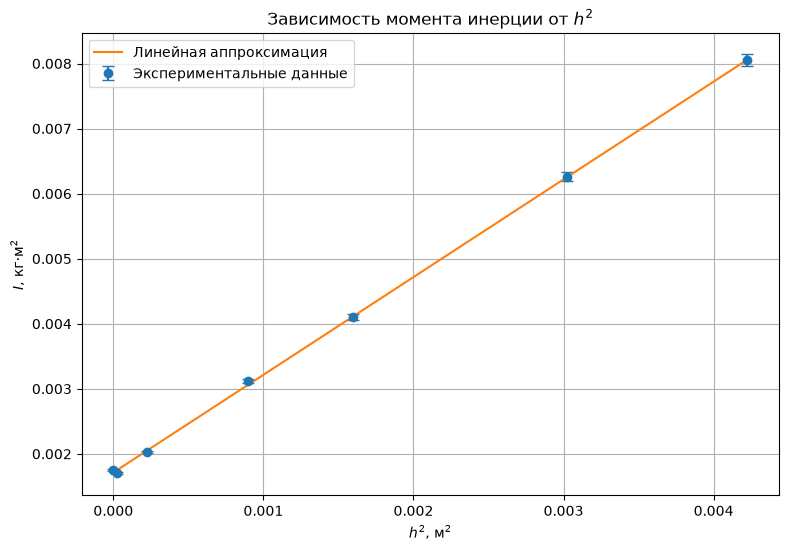

a = 1.502118 кг
b = 0.001713 кг·м²
Масса одной половинки: m = 0.7511 кг
Масса всего диска: M = 1.5021 кг
Момент инерции диска: I₀ = 0.001713 кг·м²


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

h = moment_disk['h'].to_numpy() / 1000
I = moment_disk['I, кг·м²'].to_numpy()
sigma_I = moment_disk['sigma_I, кг·м²'].to_numpy()

h2 = h**2

a, b = np.polyfit(h2, I, 1)
m = a / 2
I_0 = b

h2_line = np.linspace(0, max(h2), 100)
I_line = a * h2_line + b

plt.figure(figsize=(9, 6))

plt.errorbar(
    h2, I,
    yerr=sigma_I,
    fmt='o',
    capsize=4,
    label='Экспериментальные данные'
)

plt.plot(
    h2_line, I_line,
    label='Линейная аппроксимация'
)

plt.xlabel(r'$h^2$, м$^2$')
plt.ylabel(r'$I$, кг$\cdot$м$^2$')
plt.title(r'Зависимость момента инерции от $h^2$')

plt.grid(True)
plt.legend()
plt.show()

print(f'a = {a:.6f} кг')
print(f'b = {b:.6f} кг·м²')
print(f'Масса одной половинки: m = {m:.4f} кг')
print(f'Масса всего диска: M = {2*m:.4f} кг')
print(f'Момент инерции диска: I₀ = {I_0:.6f} кг·м²')
